# Chapter 4: Building Models with Distance Metrics and Nearest Neighbors

*Summary notebook for **scikit-learn Cookbook, Third Edition** — Chapter 4.*

Core intuition: a child can tell that a Toyota is "closer" to a car than to a cheetah. If we can measure **similarity as distance**, we can classify a new object by looking at the known objects nearest to it.

**Recipes covered**
1. Introduction to distance metrics
2. Understanding KNN (k-nearest neighbors)
3. Distance-metric comparison
4. Hyperparameter tuning of KNN (grid search + cross-validation)
5. Evaluating KNN (CV scores, learning curves, confusion matrix, classification report)
6. Practical exercises

In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option('display.precision', 3)

## 1. Introduction to Distance Metrics

### Summary
Distance metrics quantify the similarity/dissimilarity between data points, and underlie KNN, clustering, and kernel methods.

| Metric | Intuition | Typical use |
|:--|:--|:--|
| **Euclidean** | straight line ("as the crow flies") | default; continuous, scaled features |
| **Manhattan** | walk along a grid (city blocks) | high-dimensional data; more robust to outliers |
| **Minkowski** | generalisation controlled by $p$ | tune between the two |

### Theory explained
For points $\mathbf a,\mathbf b\in\mathbb R^n$:

$$d_{\text{Euclid}}=\sqrt{\sum_{i}(a_i-b_i)^2}\qquad d_{\text{Manhattan}}=\sum_i|a_i-b_i|$$

$$d_{\text{Minkowski}}(p)=\Bigl(\sum_i|a_i-b_i|^p\Bigr)^{1/p}$$

- $p=1$ → Manhattan (L1), $p=2$ → Euclidean (L2), $p\to\infty$ → Chebyshev (largest single coordinate difference).
- Squaring in Euclidean distance **penalises large coordinate differences more**, so a single outlying feature value affects it more than it affects Manhattan.
- Other metrics: *Hamming* (categorical/binary mismatches), *cosine* (angle, ignores magnitude — popular for text).

In [2]:
a, b = np.array([0, 0]), np.array([3, 4])
from scipy.spatial.distance import euclidean, cityblock, minkowski, chebyshev
print("Euclidean :", euclidean(a, b))
print("Manhattan :", cityblock(a, b))
print("Minkowski p=3:", round(minkowski(a, b, p=3), 4))
print("Chebyshev :", chebyshev(a, b))

Euclidean : 5.0
Manhattan : 7
Minkowski p=3: 4.4979
Chebyshev : 4


## 2. Understanding KNN

### Summary
KNN is a **non-parametric, instance-based ("lazy")** supervised algorithm for classification and regression. It does no real training: `fit()` just stores the data; the work happens at `predict()` time.

### Theory explained — the algorithm
To predict for a new point $\mathbf x$:
1. Compute the distance from $\mathbf x$ to **every** training point.
2. Pick the $k$ closest ones, $\mathcal N_k(\mathbf x)$.
3. **Classification:** majority vote, $\hat y=\arg\max_c\sum_{i\in\mathcal N_k}\mathbb 1[y_i=c]$.
   **Regression:** average, $\hat y=\frac1k\sum_{i\in\mathcal N_k}y_i$.

**Choosing $k$ — bias/variance trade-off.** Small $k$ (e.g. 1) → very flexible, jagged boundary, *high variance* (sensitive to noise). Large $k$ → smooth boundary, *high bias* (may miss local patterns). Use odd $k$ for binary problems to avoid ties, pick it by cross-validation or the **elbow method**.

**Practical requirements:** features must be **scaled** (otherwise large-valued features dominate the distance); performance degrades in high dimensions (curse of dimensionality); prediction is slow on big data (O(n) per query unless KD-/Ball-trees are used).

### Getting ready — Iris dataset

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2024)
print(X_train.shape, X_test.shape)

(120, 4) (30, 4)


In [4]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9333333333333333


With nothing but `k=3`, the model gets about 93% accuracy on the 30 test flowers (i.e. 2 mistakes), a good start.

### Choosing k: the elbow view

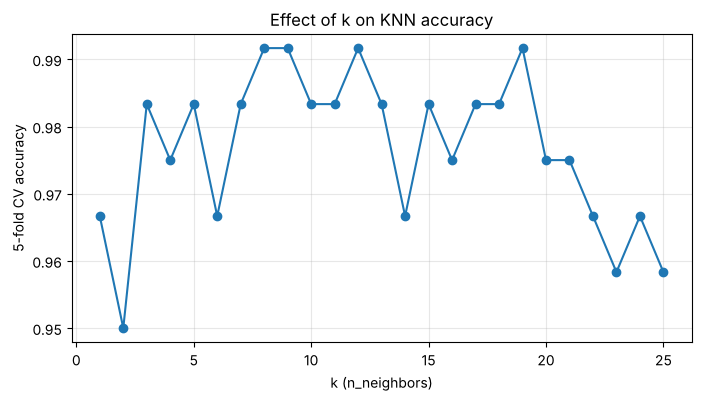

Best k: 8 | CV acc: 0.992


In [5]:
from sklearn.model_selection import cross_val_score

ks = range(1, 26)
cv_acc = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5).mean() for k in ks]
plt.figure(figsize=(8, 4))
plt.plot(ks, cv_acc, 'o-'); plt.xlabel('k (n_neighbors)'); plt.ylabel('5-fold CV accuracy')
plt.title('Effect of k on KNN accuracy'); plt.grid(alpha=.3); plt.show()
print("Best k:", list(ks)[int(np.argmax(cv_acc))], "| CV acc:", round(max(cv_acc), 3))

## 3. Distance Metrics Overview — which metric works best?

The book builds two synthetic datasets to illustrate that the best metric depends on data geometry:
- **Noisy circles** (`make_circles`, noise 0.3) — expected to favour Euclidean (round structure),
- **Checkerboard grid** — points on a regular grid, expected to favour Manhattan (axis-aligned structure).

> **Important details.**
> 1. `metric='minkowski'` with the default `p=2` **is** Euclidean, so those two columns will be identical. To get a genuinely different third metric, set `p` explicitly (e.g. `p=3`) or use `chebyshev`/`cosine`.
> 2. `make_circles` in the book has no `random_state`, so its results change on every run; the book itself admits the circles result may be luck. Here we fix the seed and repeat over many seeds to avoid over-interpreting one split.

In [6]:
from sklearn.datasets import make_circles

n_samples = 300
# Checkerboard grid
x = np.linspace(0, 4, int(np.sqrt(n_samples)))
xx, yy = np.meshgrid(x, x)
X_grid = np.column_stack((xx.ravel(), yy.ravel()))
y_grid = np.mod(np.floor(xx.ravel()) + np.floor(yy.ravel()), 2)

def evaluate(Xd, yd, metric, seed, **kw):
    Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=seed)
    m = KNeighborsClassifier(n_neighbors=3, metric=metric, **kw).fit(Xtr, ytr)
    return accuracy_score(yte, m.predict(Xte))

configs = {'euclidean': dict(metric='euclidean'),
           'manhattan': dict(metric='manhattan'),
           'minkowski (p=2 default)': dict(metric='minkowski'),
           'minkowski (p=3)': dict(metric='minkowski', p=3),
           'chebyshev': dict(metric='chebyshev')}

rows = []
for name, kw in configs.items():
    circ = np.mean([evaluate(*make_circles(n_samples, noise=0.3, factor=0.3, random_state=s), seed=s, **kw) for s in range(30)])
    grid = np.mean([evaluate(X_grid, y_grid, seed=s, **kw) for s in range(30)])
    rows.append((name, circ, grid))
pd.DataFrame(rows, columns=['Metric', 'Noisy circles (mean acc, 30 runs)', 'Checkerboard (mean acc, 30 runs)']).set_index('Metric')

,"Noisy circles (mean acc, 30 runs)","Checkerboard (mean acc, 30 runs)"
Metric,,
euclidean,0.829,0.802
manhattan,0.831,0.805
minkowski (p=2 default),0.829,0.802
minkowski (p=3),0.829,0.803
chebyshev,0.829,0.660


Averaging over 30 random splits (results will be close to, but not necessarily identical to, these numbers on a different scikit-learn/NumPy version) shows that Euclidean, Manhattan and Minkowski(p=3) are within about 0.005 of each other on both datasets — differences that small are noise, not evidence — and that `minkowski` (p=2) duplicates `euclidean`. The one clear outlier is **Chebyshev on the checkerboard**, which is much worse (about 0.66 vs about 0.80): it only looks at the single largest coordinate difference and so ignores the grid structure. Lesson: **don't pick a metric from a single split** — compare candidates with cross-validation, as the next recipe does.

### Visualising the two datasets

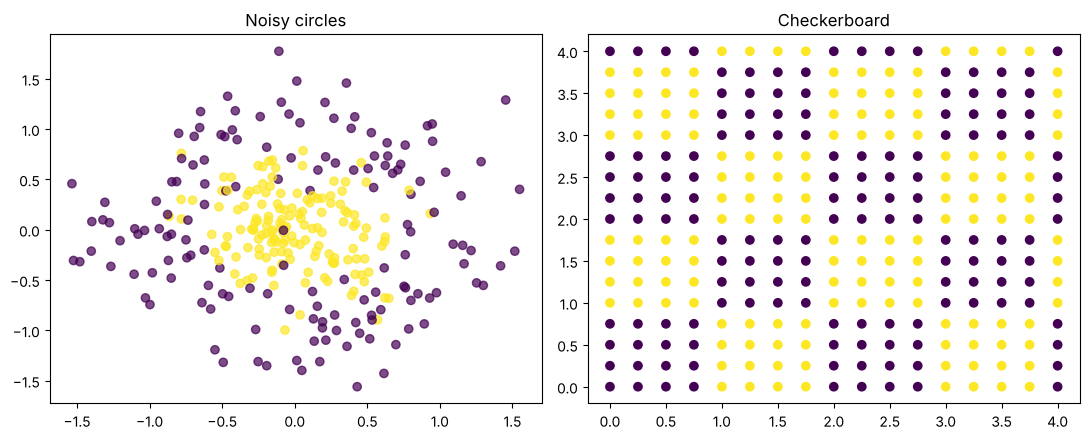

In [7]:
Xc, yc = make_circles(n_samples, noise=0.3, factor=0.3, random_state=2024)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].scatter(Xc[:, 0], Xc[:, 1], c=yc, cmap='viridis', alpha=.7); ax[0].set_title('Noisy circles')
ax[1].scatter(X_grid[:, 0], X_grid[:, 1], c=y_grid, cmap='viridis'); ax[1].set_title('Checkerboard')
plt.tight_layout(); plt.show()

### Impact on model performance
- **Scale sensitivity:** Euclidean/Manhattan are dominated by large-range features → standardize first.
- **Dimensionality:** in high dimensions all distances concentrate, so "nearest" loses meaning.
- Choose by data type: continuous → Euclidean/Manhattan; binary/categorical → Hamming; text/sparse → cosine.

## 4. Hyperparameter Tuning in KNN

### Summary
- **Parameters** are learned during training (e.g. regression coefficients). **Hyperparameters** control *how* the model learns/predicts (here `n_neighbors`, `weights`, `metric`).
- **Grid search** tries **every combination** in a grid; each combination is scored with **k-fold cross-validation** (data split into $k$ folds; train on $k-1$, validate on the held-out fold, rotate, average). This gives a more robust estimate than one train/validation split.

### Theory explained
- `weights='uniform'` → every neighbour has one vote. `weights='distance'` → a neighbour's vote is $\propto 1/d$, so closer points count more.
- Grid size = product of options (here $5\times2\times2=20$ combos × 5 folds = **100 model fits**) — it explodes as grids grow.
- **`RandomizedSearchCV`** samples a fixed number of random combinations (`n_iter`) and is far cheaper for large spaces, often with comparable results.

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_neighbors': [3, 5, 7, 9, 11],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan'],
}
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", round(grid_search.best_score_, 4))

Best parameters: {'metric': 'euclidean', 'n_neighbors': 9, 'weights': 'uniform'}
Best cross-validation score: 0.9917


Grid search reports the best combination by **mean CV accuracy on the training set**. To get an honest final estimate, evaluate the refit best model on the untouched test set (next recipe). Equivalent random version:

In [9]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

rs = RandomizedSearchCV(KNeighborsClassifier(),
                        {'n_neighbors': randint(1, 21), 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']},
                        n_iter=10, cv=5, random_state=2024)
rs.fit(X_train, y_train)
print("Randomized best:", rs.best_params_, round(rs.best_score_, 4))

Randomized best: {'metric': 'euclidean', 'n_neighbors': 8, 'weights': 'uniform'} 0.9917


## 5. Evaluating KNN Performance

We use the tuned model (`grid_search.best_estimator_`) and three views: **cross-validation scores**, **learning curves**, and **confusion matrix / classification report**.

### 5.1 Cross-validation scores

In [10]:
cv_scores = cross_val_score(grid_search.best_estimator_, X_train, y_train, cv=5)
print("Cross-validation scores:", cv_scores.round(3))
print("Mean CV score:", round(cv_scores.mean(), 4), "| std:", round(cv_scores.std(), 4))

Cross-validation scores: [0.958 1.    1.    1.    1.   ]
Mean CV score: 0.9917 | std: 0.0167


### 5.2 Learning curves
**Theory.** A learning curve plots training score and validation score against the **training-set size**.
- Both low → **underfitting** (high bias); more data won't help, need a richer model.
- Training high, validation much lower → **overfitting** (high variance); more data/regularisation helps.
- Curves converging/flat → extra data brings diminishing returns (saves compute).

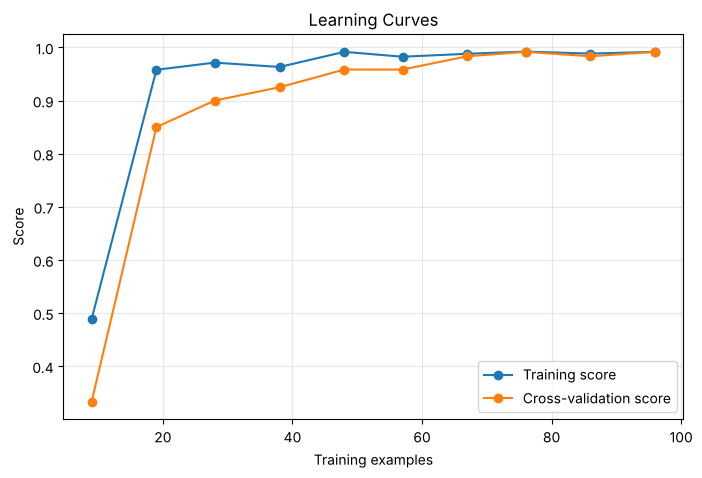

In [11]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, test_scores = learning_curve(
    grid_search.best_estimator_, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10), cv=5)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), 'o-', label='Training score')
plt.plot(train_sizes, test_scores.mean(axis=1), 'o-', label='Cross-validation score')
plt.xlabel('Training examples'); plt.ylabel('Score'); plt.legend(loc='best'); plt.title('Learning Curves'); plt.grid(alpha=.3)
plt.show()

### 5.3 Confusion matrix
**Theory.** Rows = true class, columns = predicted class. Diagonal = correct predictions; off-diagonal entries show *which* classes get confused. For a binary problem the four cells are TP, TN, FP, FN.

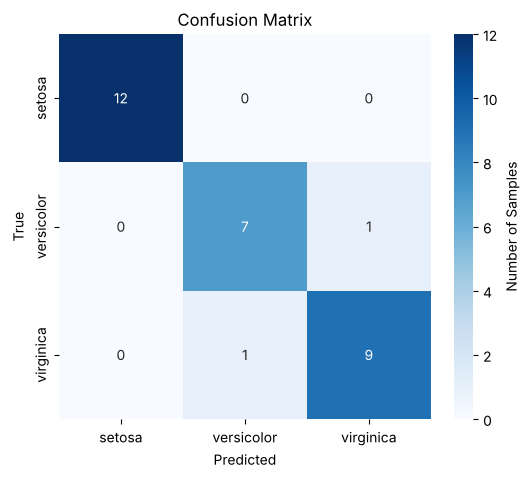

In [12]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = grid_search.best_estimator_.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names,
            cbar_kws={'label': 'Number of Samples'})
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion Matrix'); plt.show()

### 5.4 Classification report — metric definitions
$$\text{Precision}=\frac{TP}{TP+FP}\quad\text{Recall}=\frac{TP}{TP+FN}\quad F_1=\frac{2\cdot P\cdot R}{P+R}\quad\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}$$

- **Precision** – of the points I called positive, how many really were? (cost of false alarms)
- **Recall (sensitivity)** – of all real positives, how many did I find? (cost of misses)
- **F1** – harmonic mean; punishes imbalance between P and R; good for imbalanced data.
- **Macro avg** – unweighted mean over classes. **Weighted avg** – mean weighted by class support.

In [13]:
report = pd.DataFrame(classification_report(y_test, y_pred, target_names=iris.target_names, output_dict=True)).transpose()
report.style.background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score']).format(
    {'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'})

,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,12
versicolor,0.875,0.875,0.875,8
virginica,0.900,0.900,0.900,10
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.925,0.925,30
weighted avg,0.933,0.933,0.933,30


*Setosa* is usually perfectly classified (it is linearly separable from the others); errors, if any, occur between *versicolor* and *virginica*. Note that a perfect score on a toy dataset like Iris is not evidence of a great model — and in real applications "good" is defined by the business problem.

**Imbalanced data:** prefer precision–recall curves, ROC-AUC or F1 to raw accuracy; consider resampling (over/under-sampling) or `class_weight`.

---
## 6. Practical Exercises (suggested workflow)
1. **Build a KNN classifier** on a dataset of your choice (preprocess → scale → fit → predict → evaluate).
2. **Tune** with `GridSearchCV` on another dataset.
3. **Evaluate** with a confusion matrix, precision/recall/F1.

Below is a compact end-to-end solution on the Wine data, putting Chapters 2 and 4 together (scaling matters for KNN!).

In [14]:
from sklearn.datasets import load_wine
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

Xw, yw = load_wine(return_X_y=True)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, random_state=2024, stratify=yw)

raw = KNeighborsClassifier().fit(Xw_tr, yw_tr)
pipe = Pipeline([('scale', StandardScaler()), ('knn', KNeighborsClassifier())])
gs = GridSearchCV(pipe, {'knn__n_neighbors': [3, 5, 7, 9], 'knn__weights': ['uniform', 'distance'],
                         'knn__metric': ['euclidean', 'manhattan']}, cv=5).fit(Xw_tr, yw_tr)

print(f"KNN without scaling      : test acc = {raw.score(Xw_te, yw_te):.3f}")
print(f"Scaled + tuned (pipeline): test acc = {gs.score(Xw_te, yw_te):.3f}")
print("Best params:", gs.best_params_)

KNN without scaling      : test acc = 0.685
Scaled + tuned (pipeline): test acc = 0.981
Best params: {'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}


Wine features have very different ranges (e.g. proline in the hundreds/thousands vs. small-valued features), so unscaled KNN is dominated by one feature; scaling inside a pipeline fixes that and typically gives a big jump in accuracy.

---
## Chapter 4 Summary

| Topic | Key points |
|:--|:--|
| Distance | Euclidean (L2), Manhattan (L1), Minkowski (p); `minkowski` p=2 ≡ Euclidean |
| KNN | Lazy, instance-based; vote/average of $k$ nearest; sensitive to scale and $k$ |
| Tuning | `GridSearchCV` (exhaustive) vs `RandomizedSearchCV`; always cross-validate |
| Evaluation | CV scores, learning curves, confusion matrix, precision/recall/F1 |
| Pitfalls | Unscaled features, high dimensions, judging a metric from one split, imbalanced classes |